### This notebook helps to understand how a shape of mata-atoms looks like, and what data collects for library.
**Note:** almost all variables are located in conf.py.

At the beginning we repeat again first part of computations for substrait. But for structures like catenaty curvs we are needed in 3d simulation, so let's expand 2d to 3d

In [91]:
import matplotlib.pyplot as plt
import numpy as np
import meep as mp
import math

import conf

In [92]:
print(conf.cell_X)
print(conf.cell_Y)
print(conf.cell_Z)



8.0
5
4.0


Also we enable symmetry cause long-term computations. How experiments show 3d computational is not a way for preparing lib. Cause even after 30 minutes of calculation it was aborted.
I want to try preparing a simulation field in 3d however run in 2d. Is it real? I checked, that is not possible.

Нужна функция, которая будет строить объемный мета-атом, затем разрезать его и выдавать только координаты для построения этого сечения. Затем 4 точки сечения будут передаваться на 2д расчет. Предположительно 1 форму мета-атома может описывать 2-3 сечения. 

     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


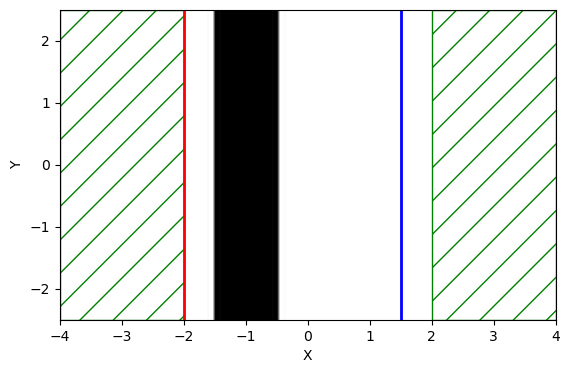

In [93]:
pml_layers = [mp.PML(thickness=conf.in_pml, direction=mp.X)]
cell = mp.Vector3(conf.cell_X, conf.cell_Y, 0)
symmetries = [mp.Mirror(mp.Y)]
geometry = [mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf, conf.cell_Z),
    center=conf.sub_center,
)]
sources = [mp.Source(
    mp.ContinuousSource(conf.inc_fcen, fwidth=conf.inc_df),
    component=mp.Ez,
    center=conf.source_center,
    size=mp.Vector3(x=0, y=conf.cell_Y, z=conf.cell_Z),
)]

sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=sources,
    resolution=conf.resolution,
    symmetries = symmetries,
)
flux_obj = sim.add_flux(
            conf.inc_fcen, 0, 1, mp.FluxRegion(center=conf.flux_center, size=mp.Vector3(y=conf.cell_Y, z=conf.cell_Z))
)
%matplotlib inline
plt.figure(dpi=100)
sim.plot2D(
    output_plane = mp.Volume(center=mp.Vector3(0, 0, 0), size=mp.Vector3(10,10,0)) 
)
plt.show()

## Note
Изменяя значения для **size** в параметре output_plane мы можем строить графики в различных направления и проверять правильно ли построена наша геометрия

In [94]:
sim.run(until=conf.steps) # run 1st part of simulation
input_flux = mp.get_fluxes(flux_obj) # saving flux from sub in input_flux
sim.reset_meep() # purge all adjustments of simulation

-----------
Initializing structure...
Halving computational cell along direction y
time for choose_chunkdivision = 0.000806093 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.00651288 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)


Следующий код позволяет нам определять точки для изогнутой кривой, которые мы теперь можем передавать как вершины полигона для class Prism(GeometricObject). 
Такой подход позволяет предварительно настроить описание геометрии, и проверить ее построив plot.

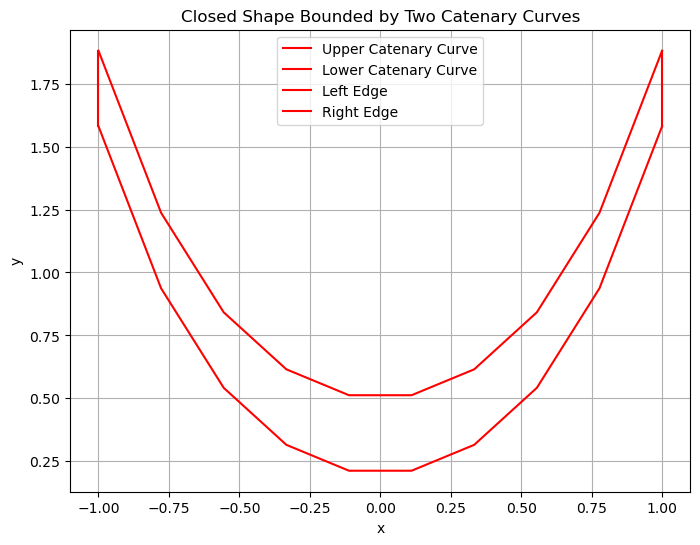

In [95]:
# Параметры цепной линии
a = 0.5  # параметр формы цепной линии
x_max = 1  # диапазон x
x_min = -x_max
width = 0.3  # ширина между двумя кривыми
num_points = 10  # количество точек

# Генерация данных для верхней и нижней кривых
x = np.linspace(x_min, x_max, num_points)
y_top = a * np.cosh(x / a)  # верхняя кривая
y_bottom = y_top - width # нижняя кривая

# Координаты концов для замыкания
y_top_left = a * np.cosh(x_min / a)
y_top_right = a * np.cosh(x_max / a)
y_bottom_left = y_top_left - width # Нужно только для построения графика, в симмуляцию эти координаты не передаются
y_bottom_right = y_top_right - width # Нужно только для построения графика, в симмуляцию эти координаты не передаются

# Построение замкнутой формы
plt.figure(figsize=(8, 6))
plt.plot(x, y_top, label='Upper Catenary Curve', color='red')
plt.plot(x, y_bottom, label='Lower Catenary Curve', color='red')
plt.plot([x_min, x_min], [y_bottom_left, y_top_left], color='red', label='Left Edge')
plt.plot([x_max, x_max], [y_bottom_right, y_top_right], color='red', label='Right Edge')

# Настройка отображения
plt.title('Closed Shape Bounded by Two Catenary Curves')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

def __init__(self,
             vertices,
             height,
             axis=Vector3<0.0, 0.0, 1.0>,
             center=None,
             sidewall_angle=0,
             **kwargs):
Construct a Prism.

vertices [list of Vector3] — The vertices that make up the prism. They must lie in a plane that's perpendicular to the axis. Note that infinite lengths are not supported. To simulate infinite geometry, just extend the edge of the prism beyond the cell.

height [number] — The prism thickness, extruded in the direction of axis. mp.inf can be used for infinite height. No default value.

axis [Vector3] — The axis perpendicular to the prism. Defaults to Vector3(0,0,1).

center [Vector3] — If center is not specified, then the coordinates of the vertices define the bottom of the prism with the top of the prism being at the same coordinates shifted by height*axis. If center is specified, then center is the coordinates of the centroid of all the vertices (top and bottom) of the resulting 3d prism so that the coordinates of the vertices are shifted accordingly.

sidewall_angle [number] — The sidewall angle of the prism in units of radians. Default is 0.

Отлично, внешний вид ячейки проверили. Но для расчета нам нужны только сечения этой геометрии. И в глобальных системах координат сечение этой геометрии вырождается 
прямоугольник, который смещается по оси Z.
Возмем 3 сечения для одной половины, т.е.
Какие константы? X для атома всегда равен его высоте (x=const), изменяются только положения вершин z1 и z2. Напишем функцию которая будет по описанию геометрии, выдавать эти вершины в соответсвии с количеством сечений. Пусть эти вершины записываются в лист list_Y_verticles, который будет содержать по 2 координаты для 2х вершин. Длина листа зависит от количенства сечений.

НО! Мы передаем размер и центр для mp.Block. А размер у нас никогда не меняется для такой ячейки. Поэтому нужно только изменять центр  

In [96]:
def solve_for_x(x0, a, const):
    # Проверка допустимости вычислений
    cosh_diff = math.cosh(x0 / a) - const / a
    if cosh_diff < 1:
        raise ValueError("Недопустимое значение: выражение под arcosh должно быть >= 1")
    
    # Вычисление x
    return a * math.acosh(cosh_diff)

In [97]:
number_sections = 10
x_sections = np.linspace(width/2, x_max, number_sections, endpoint=False, dtype=float) # точки плоскости сечения (симметричны относительно 0)
width_wide = [] # Здесь мы собираем Ширины сечений
x_centers = [] # Здесь мы собираем их относительные центры

In [98]:
def not_split(x_sections, a ,width):
    return (a * np.cosh(x_sections / a) - width) <= a

In [99]:
for i in range(number_sections):
    result = not_split(x_sections[i], a, width)
    print(result)

True
True
True
True
True
False
False
False
False
False


In [100]:
for i in range(number_sections):    
    if not_split(x_sections[i], a, width):
        x_centers.append(0)
        width_wide.append(x_sections[i]*2)     
    else:
        find_width = x_sections[i] - solve_for_x(x_sections[i], a, width )
        width_wide.append(find_width) 
        x_centers.append(x_sections[i] + width/4)

In [101]:
print(f'a coefficient equals: {a} and width equals {width}')
for i in range(number_sections):
    print(f'x_sections {i} is: {x_sections[i]:.2f} | x_centers {i} is: {x_centers[i]:.2f} | width_wide for this center is: {width_wide[i]:.2f} ')

a coefficient equals: 0.5 and width equals 0.3
x_sections 0 is: 0.15 | x_centers 0 is: 0.00 | width_wide for this center is: 0.30 
x_sections 1 is: 0.23 | x_centers 1 is: 0.00 | width_wide for this center is: 0.47 
x_sections 2 is: 0.32 | x_centers 2 is: 0.00 | width_wide for this center is: 0.64 
x_sections 3 is: 0.41 | x_centers 3 is: 0.00 | width_wide for this center is: 0.81 
x_sections 4 is: 0.49 | x_centers 4 is: 0.00 | width_wide for this center is: 0.98 
x_sections 5 is: 0.57 | x_centers 5 is: 0.65 | width_wide for this center is: 0.32 
x_sections 6 is: 0.66 | x_centers 6 is: 0.73 | width_wide for this center is: 0.22 
x_sections 7 is: 0.74 | x_centers 7 is: 0.82 | width_wide for this center is: 0.17 
x_sections 8 is: 0.83 | x_centers 8 is: 0.90 | width_wide for this center is: 0.14 
x_sections 9 is: 0.91 | x_centers 9 is: 0.99 | width_wide for this center is: 0.11 


Каждое сечение нам нужно считать, а затем очищать сборку. Причем само сечение не меняется. Меняется только расположение его центра.

In [102]:
# Хранить результаты будем в листе. Для начала инициализируем его.
mode_tran = np.empty(number_sections)
mode_phase = np.empty(number_sections)

-----------
Initializing structure...
time for choose_chunkdivision = 3.31402e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.017745 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(1.2,0,0) = 1.11442 after 19 iters
MPB solved for frequency_1(1.06647,0,0) = 0.999297 after 12 iters
MPB solved for frequency_1(1.06728,0,0) = 1 after 9 iters
MPB solved for frequency_1(1.06728,0,0) = 1 after 1 iters
Dominant planewave for band 1: (1.067278,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


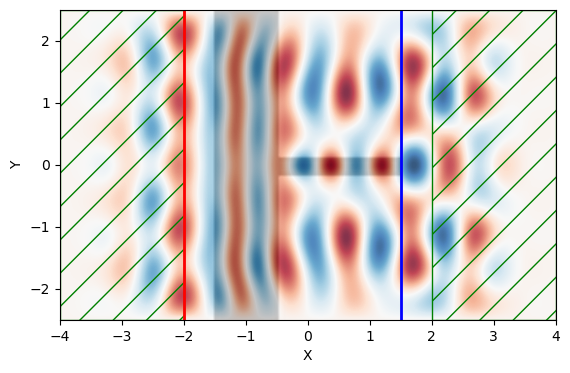

-----------
Initializing structure...
time for choose_chunkdivision = 3.00407e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.47,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.0134761 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(1.2,0,0) = 1.04766 after 16 iters
MPB solved for frequency_1(1.14014,0,0) = 0.999928 after 10 iters
MPB solved for frequency_1(1.14023,0,0) = 1 after 5 iters
MPB solved for frequency_1(1.14023,0,0) = 1 after 1 iters
Dominant planewave for band 1: (1.140232,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.47,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


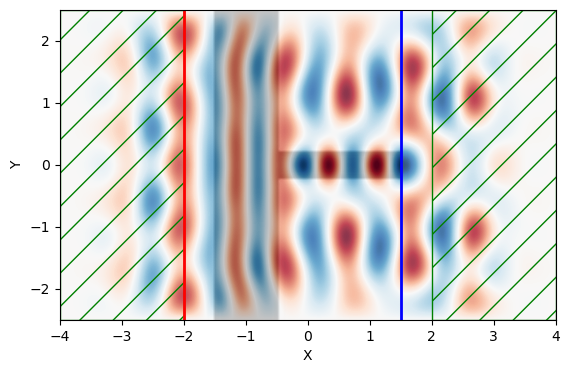

-----------
Initializing structure...
time for choose_chunkdivision = 3.00407e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.64,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.013473 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(1.2,0,0) = 1.02431 after 15 iters
MPB solved for frequency_1(1.16908,0,0) = 0.99999 after 9 iters
MPB solved for frequency_1(1.16909,0,0) = 1 after 3 iters
Dominant planewave for band 1: (1.169095,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.64,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


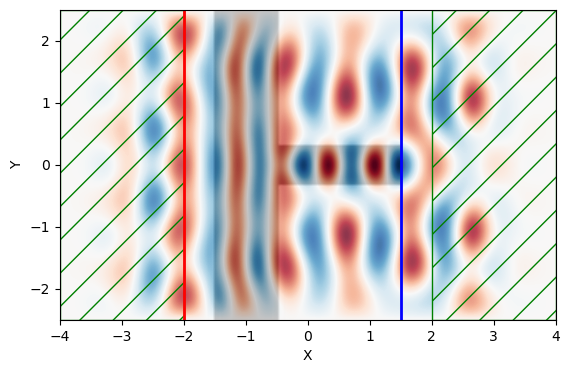

-----------
Initializing structure...
time for choose_chunkdivision = 2.98023e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.81,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.0141101 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(1.2,0,0) = 1.01 after 14 iters
MPB solved for frequency_1(1.18725,0,0) = 0.999999 after 8 iters
MPB solved for frequency_1(1.18725,0,0) = 1 after 1 iters
Dominant planewave for band 1: (1.187248,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.81,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


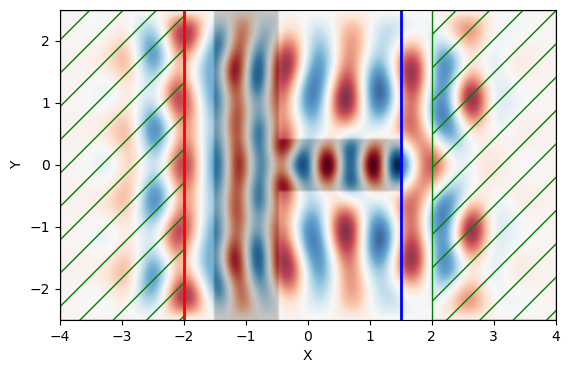

-----------
Initializing structure...
time for choose_chunkdivision = 3.21865e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.98,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.013324 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(1.2,0,0) = 1.00058 after 14 iters
MPB solved for frequency_1(1.19927,0,0) = 1 after 6 iters
MPB solved for frequency_1(1.19927,0,0) = 1 after 1 iters
Dominant planewave for band 1: (1.199266,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.98,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,0.3,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


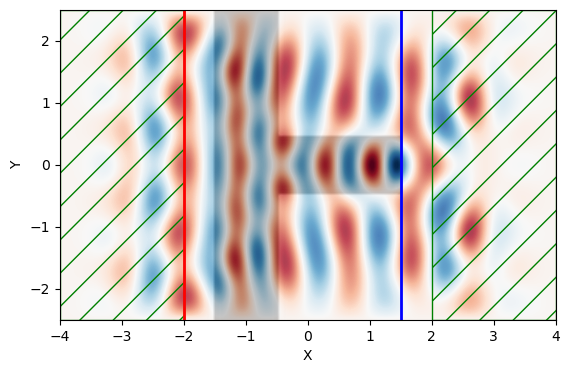

-----------
Initializing structure...
time for choose_chunkdivision = 3.29018e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0.65,0)
          size (2,0.315791,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,-0.65,0)
          size (2,0.315791,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.0134869 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(1,0,0) = 0.931885 after 18 iters
MPB solved for frequency_1(1.07737,0,0) = 0.999708 after 12 iters
MPB solved for frequency_1(1.0777,0,0) = 1 after 7 iters
MPB solved for frequency_1(1.0777,0,0) = 1 after 1 iters
Dominant planewave for band 1: (1.077704,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0.65,0)
          size (2,0.315791,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,-0.65,0)
          size (2,0.315791,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


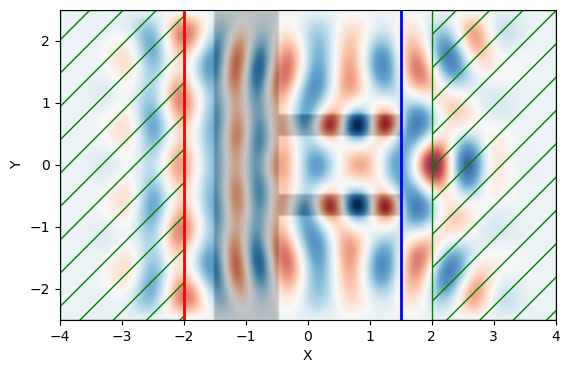

-----------
Initializing structure...
time for choose_chunkdivision = 2.98023e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0.735,0)
          size (2,0.223809,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,-0.735,0)
          size (2,0.223809,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.0131969 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(1,0,0) = 0.955118 after 20 iters
MPB solved for frequency_1(1.0491,0,0) = 0.99988 after 12 iters
MPB solved for frequency_1(1.04923,0,0) = 1 after 7 iters
MPB solved for frequency_1(1.04923,0,0) = 1 after 1 iters
Dominant planewave for band 1: (1.049233,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0.735,0)
          size (2,0.223809,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,-0.735,0)
          size (2,0.223809,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


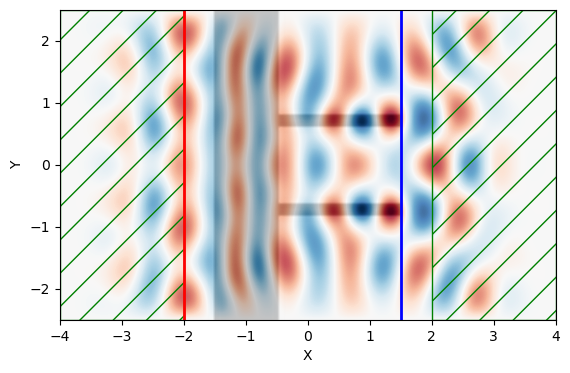

-----------
Initializing structure...
time for choose_chunkdivision = 3.09944e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0.82,0)
          size (2,0.172181,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,-0.82,0)
          size (2,0.172181,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.013891 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(1,0,0) = 0.96879 after 22 iters
MPB solved for frequency_1(1.03324,0,0) = 0.999953 after 12 iters
MPB solved for frequency_1(1.03329,0,0) = 1 after 6 iters
MPB solved for frequency_1(1.03329,0,0) = 1 after 1 iters
Dominant planewave for band 1: (1.033290,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0.82,0)
          size (2,0.172181,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,-0.82,0)
          size (2,0.172181,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


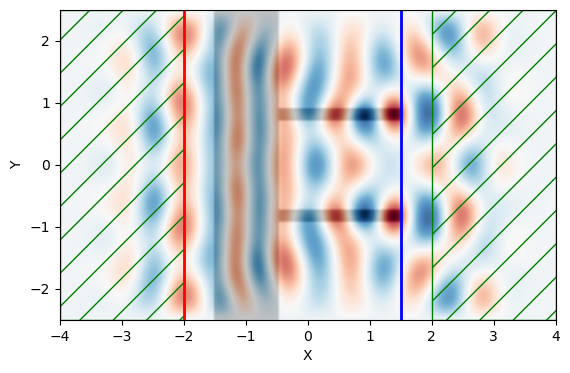

-----------
Initializing structure...
time for choose_chunkdivision = 3.88622e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0.905,0)
          size (2,0.136926,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,-0.905,0)
          size (2,0.136926,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.0141909 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(1,0,0) = 0.977794 after 22 iters
MPB solved for frequency_1(1.0232,0,0) = 0.999982 after 12 iters
MPB solved for frequency_1(1.02322,0,0) = 1 after 4 iters
MPB solved for frequency_1(1.02322,0,0) = 1 after 1 iters
Dominant planewave for band 1: (1.023216,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0.905,0)
          size (2,0.136926,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,-0.905,0)
          size (2,0.136926,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


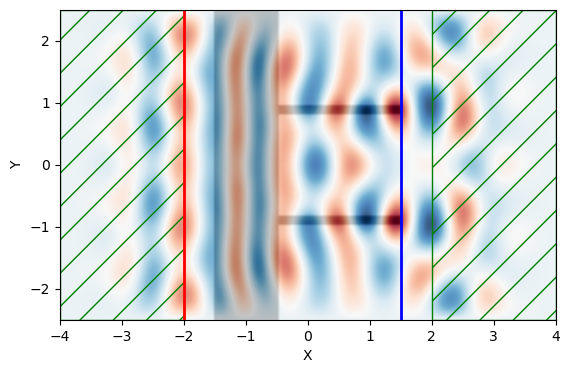

-----------
Initializing structure...
time for choose_chunkdivision = 2.88486e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0.99,0)
          size (2,0.110875,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,-0.99,0)
          size (2,0.110875,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.013217 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
MPB solved for frequency_1(1,0,0) = 0.98367 after 22 iters
MPB solved for frequency_1(1.01683,0,0) = 0.999993 after 12 iters
MPB solved for frequency_1(1.01684,0,0) = 1 after 2 iters
Dominant planewave for band 1: (1.016837,-0.000000,0.000000)
     block, center = (-1,0,2)
          size (1,1e+20,4)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0.99,0)
          size (2,0.110875,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,-0.99,0)
          size (2,0.110875,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


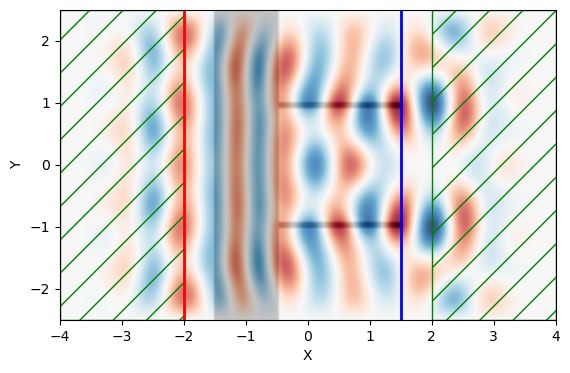

In [103]:
# Из этого нужно сделать функцию гет которая будет наполнять лист результатов. 
# Первый раз нам нужно добавить геометрию сечения, потом заменять сечение.
for i in range(number_sections):
    if i == 0:
        geometry.append(
            mp.Block(
                material=conf.at_material,
                size=mp.Vector3(x=conf.at_hei, y = width_wide[i], z = mp.inf),
                center=mp.Vector3(x = conf.at_center[0], y = x_centers[i], z = 0),
            )
        )
        
        geometry.append(
            mp.Block(
                material=conf.at_material,
                size=mp.Vector3(x=conf.at_hei, y = width_wide[i], z = mp.inf),
                center=mp.Vector3(x = conf.at_center[0], y = -x_centers[i], z = 0),
            )
        )
    
    elif x_centers[i] == 0:
        # Заменяем сечение, повторяем расчет
        geometry[1] = mp.Block(
            material=conf.at_material,
            size=mp.Vector3(x=conf.at_hei, y = width_wide[i], z = mp.inf),
            center=mp.Vector3(x = conf.at_center[0], y = x_centers[i], z = 0),
            )
    
    else:
        geometry[1] = mp.Block(
            material=conf.at_material,
            size=mp.Vector3(x=conf.at_hei, y = width_wide[i], z = mp.inf),
            center=mp.Vector3(x = conf.at_center[0], y = x_centers[i], z = 0),
        )
        
        geometry[2] = mp.Block(
            material=conf.at_material,
            size=mp.Vector3(x=conf.at_hei, y = width_wide[i], z = mp.inf),
            center=mp.Vector3(x = conf.at_center[0], y = -x_centers[i], z = 0),
        )
    
    # ---Копия кода START---
    sim = mp.Simulation(
        cell_size=cell,
        boundary_layers=pml_layers,
        geometry=geometry,
        sources=sources,
        resolution=conf.resolution,
    )
    flux_obj = sim.add_flux(
        conf.inc_fcen, 0, 1, mp.FluxRegion(
            center=mp.Vector3(x=conf.flux_center[0]), 
            size=mp.Vector3(y=conf.cell_Y)
        )
    )
    sim.run(until=conf.steps)
    
    res = sim.get_eigenmode_coefficients(
        flux_obj, [1], eig_parity=mp.ODD_Z + mp.EVEN_Y
    )
    coeffs = res.alpha
    
    mode_tran[i] = abs(coeffs[0, 0, 0]) ** 2 / input_flux[0]
    mode_phase[i] = np.angle(coeffs[0, 0, 0])
    if mode_phase[i] > 0:
        mode_phase[i] -= 2 * np.pi
        
    # Смотрим на расчет каждый шаг, заодно проверяем смещение сечения. 
    %matplotlib inline
    plt.figure(dpi=100)
    sim.plot2D(fields=mp.Ez)
    plt.show()
    sim.reset_meep() # purge all adjustments of simulation
       

In [105]:
print(mode_tran)
print(mode_phase)

[0.08422402 0.12668003 0.16473305 0.1975416  0.22416963 0.25983517
 0.23031334 0.30385226 0.40183209 0.50757936]
[-4.50518829 -3.20844215 -2.61632448 -2.2980782  -2.09855547 -4.09648917
 -5.00423847 -5.68463352 -6.09158342 -0.06966847]


Теперь накопим результаты вычислений.
